# Proyecto RappiPlus: de datos a decisiones de negocio

**Introducción**


El objetivo de este proyecto es evaluar el desempeño del servicio **RappiPlus** para apoyar **decisiones de negocio basadas en datos**.

Se trabajan con múltiples datasets del negocio:

- **rappiplus_orders_raw.csv** → información de pedidos, precios, descuentos y revenue  
- **rappiplus_catalog.csv** → costos de productos, categorías y proveedores  
- **rappiplus_marketing_spend.csv** → inversión en marketing por canal y país  
- **events / users / user_activity (SQL)** → comportamiento del usuario dentro de la plataforma  
- **experiment_checkout_ui.csv** → resultados de un experimento A/B en el checkout  

El análisis sigue una lógica clara y progresiva:

1. 🔍 Evaluar si podemos confiar en los datos (calidad de datos en Python) 

2. 💰 Analizar si el negocio es rentable (revenue, costos y profit)  

3. 🛒 Entender dónde se pierden los usuarios (funnel de conversión)  

4. 🔁 Evaluar si los usuarios regresan (retención por cohortes)  

5. 🧪 Validar si los cambios generan impacto (test estadístico)  

6. 📊 Comunicar los resultados (dashboard en BI)  

A lo largo del proyecto, se transforman datos en insights para responder preguntas clave del negocio y proponer **recomendaciones accionables**.

---

## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Verificar la estructura de los datos.

**Instrucciones:**

- Importa las librerías necesarias
- Carga los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Guarda los DataFrames en:
  - `orders`, `catalog`, `marketing`
- Explora cada dataset.

---

In [1]:
# importar librerías
import pandas as pd

In [2]:
# cargar archivos
orders = pd.read_csv('rappiplus_orders_raw.csv')
catalog = pd.read_csv('rappiplus_catalog.csv')
marketing = pd.read_csv('rappiplus_marketing_spend.csv')

In [3]:
# explorar datasets
orders.head(5)


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
catalog.head(5)

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [5]:
marketing.head(5)

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto  
- Revisar variables numéricas (sin negativos o ceros inválidos)  
- Verificar consistencia de montos  
- Eliminar duplicados  
- Revisar variables categóricas 

---

In [6]:
# verificando los tipos de datos del dataset orders
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10  monto_descuento     25050 non-null  float64
 11  monto_total         25100 non-null  float64
dtypes: float64(4), object(8)
memory usage: 2.3+ MB


In [7]:
# observando cantidad de nulos por columna
orders.isna().sum()

id_pedido               0
id_usuario              0
fecha_hora_pedido       0
pais                  300
dispositivo            20
fuente_referencia      30
nombre_producto        30
categoria_producto     80
cantidad               50
precio_unitario        50
monto_descuento        50
monto_total             0
dtype: int64

In [8]:
# observando porcentaje de nulos por columna
(orders.isna().sum()/orders.shape[0])*100

id_pedido             0.000000
id_usuario            0.000000
fecha_hora_pedido     0.000000
pais                  1.195219
dispositivo           0.079681
fuente_referencia     0.119522
nombre_producto       0.119522
categoria_producto    0.318725
cantidad              0.199203
precio_unitario       0.199203
monto_descuento       0.199203
monto_total           0.000000
dtype: float64

In [9]:
# verificando la distribución de los datos en las columnas categoricas
columnas_cate = ['pais','dispositivo','fuente_referencia','nombre_producto','categoria_producto']
for col in columnas_cate:
    
    print(f'columna {col}')
    conteo = orders[col].value_counts(dropna = False)
    resumen = pd.DataFrame({'conteo':conteo})
    print(resumen)
    print()


columna pais
           conteo
Colombia     7520
Mexico       7502
Argentina    7291
mexico        865
colombia      823
argentina     799
NaN           300

columna dispositivo
         conteo
desktop   12759
mobile    12321
NaN          20

columna fuente_referencia
             conteo
social         8428
organic        8329
paid_search    8313
NaN              30

columna nombre_producto
                      conteo
Vacuum-Pro-Black        4199
Blender-XL-Red          4195
Jacket-Winter-M         4192
Sneakers-Urban-42       4160
Laptop-Gaming-16GB      2794
Tablet-Standard-64GB    2780
Phone-Pro-128GB         2750
NaN                       30

columna categoria_producto
             conteo
Hogar          8385
Moda           8323
Electronica    8312
NaN              80



**COMENTARIO**

- El dataset `orders` presenta valores nulos en varias columnas categoricas como númericas, con la salvedad de que estos nulos por columna no llegan hacer un 5% de los registros por columna.Así que se decide reemplazar estos nulos en las columnas categoricas por `Desconocido`.

- En las columnas númericas se decide reemplazar los nulos por la mediana o media según la medida de tendencia central que explique mejor el comportamiento de los datos.

- Se observa que la columna `pais` tiene repetido algunos nombres de pais, así que se debe normalizar los nombres de los piases.

- La columna de `fecha_hora_pedido` es tipo object, así que se debe cambiar a tipo datetime.

In [10]:
# rellenar los nulos con la etiqueta 'Desconocido'
for col in columnas_cate:
    orders[col] = orders[col].fillna('Desconocido')
    
    print(f'columna {col}')
    conteo = orders[col].value_counts(dropna = False)
    resumen = pd.DataFrame({'conteo':conteo})
    print(resumen)
    print()


columna pais
             conteo
Colombia       7520
Mexico         7502
Argentina      7291
mexico          865
colombia        823
argentina       799
Desconocido     300

columna dispositivo
             conteo
desktop       12759
mobile        12321
Desconocido      20

columna fuente_referencia
             conteo
social         8428
organic        8329
paid_search    8313
Desconocido      30

columna nombre_producto
                      conteo
Vacuum-Pro-Black        4199
Blender-XL-Red          4195
Jacket-Winter-M         4192
Sneakers-Urban-42       4160
Laptop-Gaming-16GB      2794
Tablet-Standard-64GB    2780
Phone-Pro-128GB         2750
Desconocido               30

columna categoria_producto
             conteo
Hogar          8385
Moda           8323
Electronica    8312
Desconocido      80



In [11]:
# Normalizar la columna 'pais'
orders['pais'] = orders['pais'].str.strip().str.capitalize()
orders['pais'].value_counts(dropna = False)

Mexico         8367
Colombia       8343
Argentina      8090
Desconocido     300
Name: pais, dtype: int64

In [12]:
# verificando cantidades y valores improbables en las columnas numéricas
columnas_nu = ['cantidad','precio_unitario','monto_descuento','monto_total']

resultados = []
for col in columnas_nu:
    valor_cero = (orders[col] == 0).sum()
    negativos = (orders[col] < 0).sum()
    nulos = orders[col].isna().sum()
    resultados.append({'columna':col,
                      'valor_cero':valor_cero,
                      'negativos':negativos,
                      'nulos':nulos})
    resumen = pd.DataFrame(resultados)
    
print(resumen)
    

           columna  valor_cero  negativos  nulos
0         cantidad           0          4     50
1  precio_unitario           0          0     50
2  monto_descuento       12551          0     50
3      monto_total           0          4      0


In [13]:
# resumen de las columnas numéricas
resultados = []
for col in columnas_nu:
    minimo = orders[col].min()
    media = orders[col].mean()
    mediana = orders[col].median()
    maximo = orders[col].max()
    resultados.append ({'columna': col,
                        'minimo': minimo,
                       'media': media,
                       'mediana': mediana,
                       'maximo': maximo})
    resumen = pd.DataFrame(resultados)

print(resumen)
    
   

           columna  minimo        media  mediana      maximo
0         cantidad   -2.00     7.092735    2.000    20000.00
1  precio_unitario   20.03   259.305549  258.715      499.96
2  monto_descuento    0.00     4.500798    0.000       15.00
3      monto_total -492.65  2072.679584  341.750  8840200.00


**COMENTARIO**

- con las columnas numércias que poseen valores nulos y valores negativos que en proporción no son significantes, los negativos se pueden eliminar y los nulos se pueden imputar por la media o mediana sin incurrir en un sesgo.

In [14]:
# Filtrar filas donde la cantidad sea < 0 O el monto_total sea < 0
anomalias_negativas = orders[(orders['cantidad'] < 0) | (orders['monto_total'] < 0)]

print(f"Total de registros con valores negativos: {len(anomalias_negativas)}")
display(anomalias_negativas)


Total de registros con valores negativos: 4


,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
266,order_266,user_7011,2025-03-13,Desconocido,desktop,paid_search,Phone-Pro-128GB,Electronica,-2.0,101.31,10.0,-192.62
267,order_267,user_1087,2025-05-07,Desconocido,desktop,social,Phone-Pro-128GB,Electronica,-1.0,43.50,5.0,-38.50
268,order_268,user_84,2025-02-19,Desconocido,desktop,organic,Phone-Pro-128GB,Electronica,-1.0,497.65,5.0,-492.65
269,order_269,user_3323,2025-05-25,Desconocido,desktop,paid_search,Phone-Pro-128GB,Electronica,-1.0,423.53,0.0,-423.53


**COMENTARIO**

- La tabla anterior nos permite ver que los valores negativos estan realcionados a un país desconocido, como tambien a un dispostivo en particular donde las ordenes son ejecutadas por distintos usuarios y en distitas fechas, así que con esto claro se pueden excluir del conjunto de datos.

In [15]:
# excluir valores negativos del dataset orders.
orders = orders[(orders['cantidad'] >= 0) & (orders['monto_total'] >= 0)]
orders.describe()

,cantidad,precio_unitario,monto_descuento,monto_total
count,25046.000000,25046.000000,25046.000000,2.504600e+04
mean,7.094067,259.304400,4.500719,2.076331e+03
std,296.300643,138.715188,5.223232,9.905653e+04
min,1.000000,20.030000,0.000000,5.240000e+00
25%,1.000000,138.405000,0.000000,1.804025e+02
50%,2.000000,258.715000,0.000000,3.415600e+02
75%,2.000000,380.272500,10.000000,5.184375e+02
max,20000.000000,499.960000,15.000000,8.840200e+06


In [16]:
# imputar valores nulos de las columnas numéricas
columnas_num = ['cantidad','precio_unitario','monto_descuento']
for col in columnas_num:
    orders[col] = orders[col].fillna(orders[col].median())
    print(col)
    print(orders[col].isna().sum())
    print
    

cantidad
0
precio_unitario
0
monto_descuento
0


In [17]:
# convertir la columna fecha_hora_pedido a datetime
orders['fecha_hora_pedido'] = pd.to_datetime(orders['fecha_hora_pedido'], errors = 'coerce')
print('cantida de nulos')
print(orders['fecha_hora_pedido'].isna().sum())

cantida de nulos
0


In [18]:
# Verificación de los cambios.
orders.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25046 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25046 non-null  object        
 1   id_usuario          25046 non-null  object        
 2   fecha_hora_pedido   25046 non-null  datetime64[ns]
 3   pais                25046 non-null  object        
 4   dispositivo         25046 non-null  object        
 5   fuente_referencia   25046 non-null  object        
 6   nombre_producto     25046 non-null  object        
 7   categoria_producto  25046 non-null  object        
 8   cantidad            25046 non-null  float64       
 9   precio_unitario     25046 non-null  float64       
 10  monto_descuento     25046 non-null  float64       
 11  monto_total         25046 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.5+ MB


### Evaluar los conjuntos de datos de catalogo y marketing

In [19]:
# verificar tipos de datos
catalog.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes


In [20]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB


**COMENTARIO**

- El dataset de `catalog` no presenta inconsistencia con los tipos de datos, ni valores nulos
- El dataset de `marketing` presenta valores nulos en la columna `canal` y la columna fecha es tipo object.

In [21]:
# verificando normalización y valores unicos

columnas_catalog = ['nombre_producto','categoria_producto','costo_unitario','proveedor']

for col in columnas_catalog:
    print(f'columna {col}')
    conteo = catalog[col].value_counts(dropna = False)
    resumen = pd.DataFrame({'conteo':conteo})
    print(resumen)
    print()


columna nombre_producto
                      conteo
Sneakers-Urban-42          1
Jacket-Winter-M            1
Tablet-Standard-64GB       1
Vacuum-Pro-Black           1
Laptop-Gaming-16GB         1
Blender-XL-Red             1
Phone-Pro-128GB            1

columna categoria_producto
             conteo
Electrónica       3
Hogar             2
Moda              2

columna costo_unitario
        conteo
189.31       1
280.68       1
16.60        1
25.21        1
176.64       1
17.21        1
10.12        1

columna proveedor
                         conteo
Mcmillan-Rhodes               1
King Ltd                      1
Long-Reid                     1
Fuller, Pena and Myers        1
Greene-Smith                  1
Rivera, Carr and Finley       1
Bowers LLC                    1



In [22]:
columnas_mark = ['pais','id_campaña','canal']

for col in columnas_mark:
    print(f'columna {col}')
    conteo = marketing[col].value_counts(dropna = False)
    resumen = pd.DataFrame({'conteo':conteo})
    print(resumen)
    print()

columna pais
           conteo
Colombia      540
Argentina     540
Mexico        540

columna id_campaña
                       conteo
paid_search_Mexico        180
organic_Mexico            180
paid_search_Argentina     180
paid_search_Colombia      180
social_Colombia           180
organic_Argentina         180
social_Argentina          180
organic_Colombia          180
social_Mexico             180

columna canal
             conteo
paid_search     507
social          506
organic         506
NaN             101



**COMENTARIO**

- En cuanto al dataset `catalog` no presenta la necesidad de normalizar datos, ni presenta valores duplicados.
- El dataset `marketing` como unica novedad son los 101 nulos en la columna `canal`, no presenta valores duplicados, los datos están normalizados

In [23]:
# verificar si los nulos de la columna canal son aleatorios
marketing['canal'].isna().groupby(marketing['id_campaña']).mean().sort_values(ascending = False)

id_campaña
organic_Mexico           0.066667
social_Argentina         0.066667
organic_Argentina        0.061111
organic_Colombia         0.061111
paid_search_Argentina    0.061111
paid_search_Colombia     0.061111
paid_search_Mexico       0.061111
social_Colombia          0.061111
social_Mexico            0.061111
Name: canal, dtype: float64

**COMENTARIO**

- Según la prorporción con que se distribuyen los nulos por tipo de campaña no parece haber una relación o dependencia hacia una en especifico, así que los nulos son aleatorios.

In [24]:
# imputar los nulos por el tipo de campaña a la que corresponden

datos_nulos = marketing['canal'].isna()

marketing.loc[datos_nulos & marketing['id_campaña'].str.contains('organic', case=False, na=False), 'canal'] = 'organic'
marketing.loc[datos_nulos & marketing['id_campaña'].str.contains('social', case=False, na=False), 'canal'] = 'social'
marketing.loc[datos_nulos & marketing['id_campaña'].str.contains('paid_search', case=False, na=False), 'canal'] = 'paid_search'

print(f"Nulos restantes en 'canal': {marketing['canal'].isna().sum()}")
print()
print(marketing['canal'].value_counts(dropna = False))

Nulos restantes en 'canal': 0

paid_search    540
social         540
organic        540
Name: canal, dtype: int64


In [25]:
# transforma la coluna fecha tipo date time
marketing['fecha'] = pd.to_datetime(marketing['fecha'], errors = 'coerce')

# verificamos le dataset marketing
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1620 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


In [26]:
# verificar que no halla valores negativos 
marketing['gasto'].describe()

count    1620.00000
mean     1772.74292
std       734.43294
min       501.11000
25%      1128.03000
50%      1782.42500
75%      2420.68500
max      2999.36000
Name: gasto, dtype: float64

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [27]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [1]:
# importar libreria
import pandas as pd


In [2]:
#cargar datesets limpios
orders_clean = pd.read_csv('orders_clean.csv')
catalog_clean = pd.read_csv('catalog_clean.csv')
marketing_clean = pd.read_csv('marketing_clean.csv')

In [3]:
orders_clean.head(5)

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [4]:
catalog_clean.head(5)

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [5]:
marketing_clean.head(5)

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


In [6]:
# union entre orders_clean y catalog_clean

orders_prod = pd.merge(orders_clean,catalog_clean[['nombre_producto','costo_unitario']],
                      on = 'nombre_producto', how = 'left')

In [7]:
orders_prod.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,costo_unitario
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37,189.31
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86,25.21
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99,176.64
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87,25.21
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28,176.64


In [8]:
# verificar la unión
orders_prod.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 25046 entries, 0 to 25045
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25046 non-null  object 
 1   id_usuario          25046 non-null  object 
 2   fecha_hora_pedido   25046 non-null  object 
 3   pais                25046 non-null  object 
 4   dispositivo         25046 non-null  object 
 5   fuente_referencia   25046 non-null  object 
 6   nombre_producto     25046 non-null  object 
 7   categoria_producto  25046 non-null  object 
 8   cantidad            25046 non-null  float64
 9   precio_unitario     25046 non-null  float64
 10  monto_descuento     25046 non-null  float64
 11  monto_total         25046 non-null  float64
 12  costo_unitario      25016 non-null  float64
dtypes: float64(5), object(8)
memory usage: 2.7+ MB


In [9]:
# identificar a que se deben los valores nulos de la columna costo_unitario
nulos = orders_prod[orders_prod['costo_unitario'].isna()]
nulos.head(5)

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total,costo_unitario
44,order_44,user_2899,2025-02-22,Colombia,desktop,Desconocido,Desconocido,Desconocido,1.0,318.38,5.0,313.38,NaN
45,order_45,user_6196,2025-02-10,Mexico,mobile,Desconocido,Desconocido,Desconocido,2.0,354.06,10.0,698.12,NaN
46,order_46,user_5815,2025-04-24,Mexico,mobile,Desconocido,Desconocido,Desconocido,1.0,359.31,10.0,349.31,NaN
47,order_47,user_406,2025-05-08,Colombia,mobile,Desconocido,Desconocido,Desconocido,2.0,476.78,0.0,953.56,NaN
48,order_48,user_6187,2025-01-26,Colombia,desktop,Desconocido,Desconocido,Desconocido,2.0,137.96,0.0,275.93,NaN


**COMENTARIO**

- Los nulos de la columna `costo_unitario` se debe a que no tener con que relacionar el costo del producto con un nombre de producto, este registro se vuelve nulo.
-  Este detalle se ignorara para calculo de beneficos y costos ya que son 30 registros y no suponen un volumen alto de datos.

In [10]:
# que medida de tendencia central explica mejor el comportamiento de la columna costo_unitario
media = orders_prod['costo_unitario'].mean()
mediana = orders_prod['costo_unitario'].median()

print(f'media: {media}')
print(f'mediana: {mediana}')

media: 102.088815957787
mediana: 25.21


In [11]:
# inputar nulos de la columna costo_unitario con la mediana
orders_prod['costo_unitario'] = orders_prod['costo_unitario'].fillna(mediana)
orders_prod['costo_unitario'].isna().sum()

0

In [39]:
#Guardar unión 
orders_prod.to_csv('orders_clean_.csv', index=False)

In [12]:
# Calculo de metricas de rentabilidad
ingreso_total = orders_prod['monto_total'].sum()
print(f"Ingreso total: ${ingreso_total:,.2f}")

Ingreso total: $52,003,776.86


In [13]:
costo_total = (orders_prod['cantidad']*orders_prod['costo_unitario']).sum()
print(f"Costo total de los productos: ${costo_total:,.2f}")

Costo total de los productos: $43,141,805.51


In [14]:
beneficio = ingreso_total - costo_total
print(f'benefio obtenido: ${beneficio:,.2f}')

benefio obtenido: $8,861,971.35


In [15]:
gasto_marketing = marketing_clean['gasto'].sum()
print(f'gasto total marketing: ${gasto_marketing:,.2f}')

gasto total marketing: $2,871,843.53


In [16]:
# importar librerias para gráficas
import matplotlib.pyplot as plt
import seaborn as sns

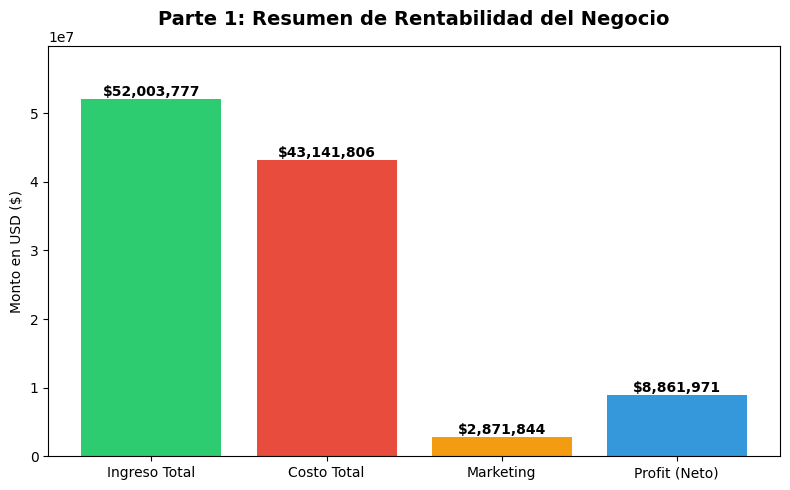

In [18]:
# Rentabilidad del negocio
finanzas = pd.DataFrame({"Concepto": ["Ingreso Total", "Costo Total", "Marketing", "Profit (Neto)"],
    "Monto": [ingreso_total, costo_total, gasto_marketing, beneficio]})

# Gráfico 1: Resumen Financiero (Barras)
plt.figure(figsize=(8, 5))
colores = ["#2ecc71", "#e74c3c", "#f39c12", "#3498db"]
bars = plt.bar(finanzas["Concepto"], finanzas["Monto"], color=colores)

plt.title(
    "Parte 1: Resumen de Rentabilidad del Negocio",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.ylabel("Monto en USD ($)")

# Añadir las etiquetas de valor encima de cada barra
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      yval + 1500,
      f"${yval:,.0f}",
      ha="center",
      va="bottom",
      fontweight="bold",
  )

plt.ylim(0, max(finanzas["Monto"]) * 1.15)
plt.tight_layout()
plt.show()

**COMENTARIO**

- El negocio de muestra ser rentable al obtener un beneficio de $8,861,971
- Si se le restara el gasto total en marketing se obtendria un beneficio neto de alrededor de 6 millones.

In [44]:
# calculo de metricas de comportamiento de las ventas

ticket_promedio = orders_prod.groupby('id_pedido')['monto_total'].sum().mean()
print(f"Ticket promedio por orden: ${ticket_promedio:,.2f}")

Ticket promedio por orden: $2,084.65


In [45]:
# Cantidad promedio de productos por orden
cant_productos_promedio = orders_prod.groupby('id_pedido')['cantidad'].sum().mean()
print(f"Cantidad promedio de productos por orden: {cant_productos_promedio:.2f} unidades")

Cantidad promedio de productos por orden: 7.12 unidades


In [46]:
# producto mas vendidos
ventas_por_producto = orders_prod.groupby('nombre_producto')['cantidad'].sum()

# Identificamos el de mayor valor
producto_top = ventas_por_producto.idxmax()
unidades_top = ventas_por_producto.max()

print(f"El producto más vendido es: '{producto_top}' con {unidades_top:,.0f} unidades.")

El producto más vendido es: 'Laptop-Gaming-16GB' con 144,219 unidades.


In [36]:
# Gasto publicitario por canal
gasto_por_canal = marketing_clean.groupby('canal')['gasto'].sum()
    
print("Inversión total en marketing por canal:")
print(gasto_por_canal.apply(lambda x: f"${x:,.2f}"))

Inversión total en marketing por canal:
canal
organic        $972,650.96
paid_search    $922,374.20
social         $976,818.37
Name: gasto, dtype: object


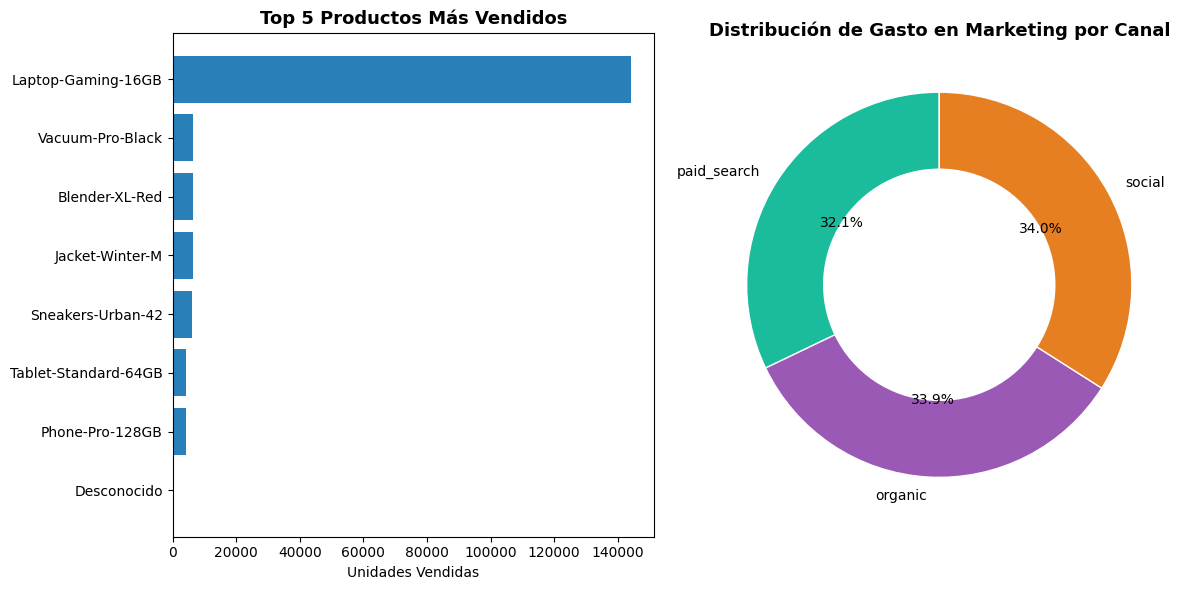

In [42]:
# Gráfico del comportamiento en ventas
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Productos más vendidos
venta_prod = (orders_prod.groupby('nombre_producto')['cantidad']
    .sum()
    .reset_index(name = 'cantidad')
    .sort_values('cantidad',ascending = True))

# Producto más vendido (Barras horizontales)
axes[0].barh(
    venta_prod["nombre_producto"],
    venta_prod["cantidad"],
    color="#2980b9",
)
axes[0].set_title(
    "Top 5 Productos Más Vendidos", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Unidades Vendidas")

# dataframe de gasto por canal
gasto_por_canal = (marketing_clean.groupby('canal')['gasto']
    .sum()
    .reset_index(name = 'gasto')
    .sort_values('gasto',ascending = True))

# Marketing por Canal (Gráfico de Torta / Donut)
axes[1].pie(
    gasto_por_canal["gasto"],
    labels=gasto_por_canal["canal"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#1abc9c", "#9b59b6", "#e67e22", "#34495e"],
    wedgeprops={"width": 0.4, "edgecolor": "w"},
)  # 'width' crea el efecto de gráfico de dona
axes[1].set_title(
    "Distribución de Gasto en Marketing por Canal", fontsize=13, fontweight="bold"
)

plt.tight_layout()
plt.show()

**COMENTARIO**

- Ticket promedio de $2,084.65
- Cantidad promedio de productos por orden de 7.12 unidades
- Producto mas vendido es la 'Laptop-Gaming-16GB' con 144,219 unidades.
- La inversión en marketing ha sido bastante similar entre canales con una distribución de alrededor del 33 porciento por canal


## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [44]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión (NO modificar)
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [45]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [46]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios_unicos
FROM events
GROUP BY nombre_evento
ORDER BY 
    CASE nombre_evento
        WHEN 'first_visit' THEN 1
        WHEN 'select_item' THEN 2
        WHEN 'add_to_cart' THEN 3
        WHEN 'begin_checkout' THEN 4
        WHEN 'add_payment_info' THEN 5
        WHEN 'purchase' THEN 6
    END ASC;
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,usuarios_unicos
0,first_visit,7796
1,select_item,7582
2,add_to_cart,7634
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


In [47]:
# PARTE 2: Conversiones
# ======================

query_conversion = '''
WITH cte_funnel_base AS(
 SELECT nombre_evento,
        COUNT(DISTINCT id_usuario) AS usuarios_unicos,
        CASE nombre_evento
            WHEN 'first_visit' THEN 1
            WHEN 'select_item' THEN 2
            WHEN 'add_to_cart' THEN 3
            WHEN 'begin_checkout' THEN 4
            WHEN 'add_payment_info' THEN 5
            WHEN 'purchase' THEN 6
        END AS orden_evento
 FROM events
 GROUP BY nombre_evento
)
SELECT 
    nombre_evento,
    usuarios_unicos,
    ROUND(100 * usuarios_unicos / FIRST_VALUE(usuarios_unicos) OVER (ORDER BY orden_evento),2) AS conversion_desde_inicio_ptc,
    ROUND(100 * usuarios_unicos / LAG(usuarios_unicos,1) OVER (ORDER BY orden_evento),2) AS conversion_paso_anterior_ptc
FROM cte_funnel_base;
'''

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,nombre_evento,usuarios_unicos,conversion_desde_inicio_ptc,conversion_paso_anterior_ptc
0,first_visit,7796,100.0,NaN
1,select_item,7582,97.0,97.0
2,add_to_cart,7634,97.0,100.0
3,begin_checkout,7208,92.0,94.0
4,add_payment_info,6250,80.0,86.0
5,purchase,6240,80.0,99.0


**COMENTARIO**

- Respecto a la anomalía observada entre los eventos select_item y add_to_cart, se identifica que el número de usuarios únicos en el carrito (7,634) supera al paso previo de selección (7,582). Esto ocurre debido a un comportamiento de navegación no lineal: los usuarios ingresan directamente a las páginas de producto mediante accesos directos, motores de búsqueda o campañas, omitiendo el evento de selección general. Adicionalmente, esto puede reflejar una pequeña brecha en el registro del evento select_item por parte del sistema de tracking. Como consecuencia matemática, la tasa real sobre el paso anterior supera el 100% (~100.68%), la cual se visualiza limitada al 100% por la estructura del cálculo actual.
  
- la etapa de menor conversión es en add_payment_info, posiblemente al usuario se le pide mucha información y esto hace que pierda el interes en la compra.

- La tasa de conversión desde la etapa first_visit hasta purchase es de 80%

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  



In [48]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [53]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [49]:
# Definir cohorte
#==========================

query_cohorte = '''
SELECT id_usuario,
       TO_CHAR(CAST(fecha_registro AS DATE), 'YYYY-MM') AS fecha_cohorte,
       país,
       dispositivo,
       tipo_plan
FROM users
'''
cohorte = pd.read_sql(query_cohorte, con=engine)
cohorte['fecha_cohorte'].value_counts()

2025-05    1687
2025-03    1636
2025-01    1627
2025-04    1606
2025-02    1444
Name: fecha_cohorte, dtype: int64

In [52]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH cte_cohorte AS(
 SELECT id_usuario,
        TO_CHAR(CAST(fecha_registro AS DATE),'YYYY-MM') AS fecha_cohorte
 FROM users
),
cte_actividad_cohorte AS(
SELECT 
    c.fecha_cohorte,
    a.id_usuario,
    a.dias_despues_registro,
    a.activo
FROM user_activity AS a
JOIN cte_cohorte AS c 
ON a.id_usuario = c.id_usuario
),
cte_tamaño_inicial AS(
SELECT 
    fecha_cohorte,
    COUNT(DISTINCT id_usuario) AS total_inicial
FROM cte_actividad_cohorte
GROUP BY fecha_cohorte
),
cte_retencion_semanal AS(
SELECT
    fecha_cohorte,
    COUNT(DISTINCT CASE WHEN dias_despues_registro = 7 AND activo = 1 THEN id_usuario END) AS retenido_w1,
    COUNT(DISTINCT CASE WHEN dias_despues_registro = 14 AND activo = 1 THEN id_usuario END) AS retenido_w2,
    COUNT(DISTINCT CASE WHEN dias_despues_registro = 21 AND activo = 1 THEN id_usuario END) AS retenido_w3
FROM cte_actividad_cohorte
GROUP BY fecha_cohorte
)

SELECT
    r.fecha_cohorte,
    t.total_inicial,
    r.retenido_w1,
    r.retenido_w2,
    r.retenido_w3,
    ROUND(100 * r.retenido_w1 / t.total_inicial,2) AS semana_1,
    ROUND(100 * r.retenido_w2 / t.total_inicial,2) AS semana_2,
    ROUND(100 * r.retenido_w3 / t.total_inicial,2) AS semana_3
    
FROM cte_retencion_semanal AS r
JOIN cte_tamaño_inicial AS t
ON r.fecha_cohorte = t.fecha_cohorte
ORDER BY r.fecha_cohorte

'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)

cohorte_final

,fecha_cohorte,total_inicial,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2025-01,1627,697,668,656,42.0,41.0,40.0
1,2025-02,1444,611,609,635,42.0,42.0,43.0
2,2025-03,1636,677,705,690,41.0,43.0,42.0
3,2025-04,1606,680,697,663,42.0,43.0,41.0
4,2025-05,1687,695,676,706,41.0,40.0,41.0


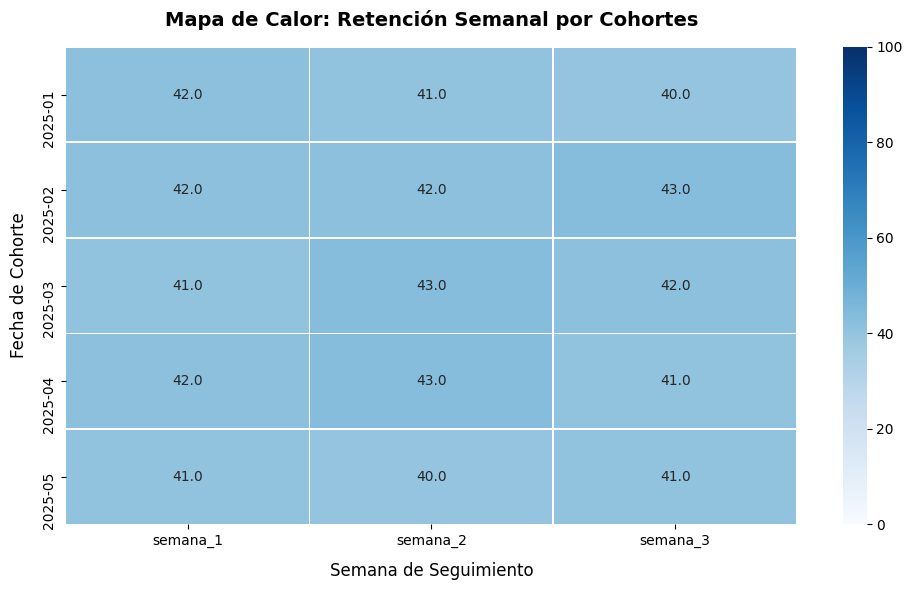

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

df_heatmap = cohorte_final.set_index("fecha_cohorte")[
    ["semana_1", "semana_2", "semana_3"]
]

#  Crear mapa de calor
plt.figure(figsize=(10, 6))

sns.heatmap(
    df_heatmap,
    annot=True,  
    fmt=".1f",  
    cmap="Blues",  
    cbar=True,  
    linewidths=0.5,  
    vmin=0,
    vmax=100,  
)

plt.title(
    "Mapa de Calor: Retención Semanal por Cohortes",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xlabel("Semana de Seguimiento", fontsize=12, labelpad=10)
plt.ylabel("Fecha de Cohorte", fontsize=12, labelpad=10)

# Ajustar diseño y mostrar gráfico
plt.tight_layout()
plt.show()

**COMENTARIO**

- Se observa una proporción de retención por cohorte bastante similar entre 40% y 43%, esto indica un habito muy solido y estandarizado del usuario
- En las cohortes del 2025-03 y 2025-04 en la semana 3 hay un subida de retención a 43%.Esto muestra que los usuarios se estabilizan al pasar la fricción de compra
- Es de notar que en la semana 1 todas las cohortes bajan un casi un 60% de usuarios.
- En general se aprecia una base consistentes de usuarios iniciales como de los retenidos por semana, se debe analizar los factores que hacen obtener esas pequeñas subidas en la retención.

---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

In [ ]:
# Cargar datos
import pandas as pd
df = pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')
df.head()

,id_usuario,variante,convirtio,dispositivo,pais,duracion_sesion,timestamp
0,exp_user_0,tratamiento,0,mobile,Argentina,114.41,2025-03-28
1,exp_user_1,tratamiento,0,desktop,Mexico,170.03,2025-01-15
2,exp_user_2,control,1,mobile,Colombia,140.21,2025-03-18
3,exp_user_3,tratamiento,0,mobile,Colombia,151.45,2025-06-03
4,exp_user_4,tratamiento,0,desktop,Mexico,299.96,2025-01-12


In [57]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


In [58]:
# Separación de grupos para comparar promedios
grupo_A = df[(df['variante']=='control') & (df['convirtio'] == 1)]['duracion_sesion']
grupo_B = df[(df['variante']=='tratamiento') & (df['convirtio'] == 1)]['duracion_sesion']

len(grupo_A),len(grupo_B)

(779, 820)

In [59]:
data = pd.DataFrame({'Variante':['control','tratamiento'],
                    'tiempo promedio':[grupo_A.mean(),grupo_B.mean()]})
display(data)

,Variante,tiempo promedio
0,control,162.421656
1,tratamiento,158.050927


**Hipótesis test de t para promedios**

- *H0*: No hay diferencias significativas en el tiempo de sesión entre la variante de control y de tratamiento.

- *H1*: Hay diferencias significativas en el tiempo de sesión entre la variante de control y de tratamiento

In [60]:
# Calculo de prueba de hipóetesis
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(grupo_A,grupo_B)
print(f'Estadisti: {t_stat}')
print(f'Valor_p: {p_value}')

if p_value < 0.05:
    print('Se rechaza la hipotesis nula y hay diferencias significativas entre los tiempos de sesión')
else:
    print('No se rechaza la hipotesis nula y no hay diferencias significativas entre los tiempos de sesion')

Estadisti: 1.0596284409665528
Valor_p: 0.28947390328346456
No se rechaza la hipotesis nula y no hay diferencias significativas entre los tiempos de sesion


**Hipótesis test de varianzas**

- *H0*: No hay diferencias entre las varinzas de ambos grupos
- *H1*: Hay diferencias entre las varianzas de ambos grupos

In [61]:
# Prueba de Levene test de varianzas
from scipy.stats import levene

l_stat, p_value = levene(grupo_A,grupo_B)

print(f'Estadístico Levene: {l_stat}')
print(f'valor p: {p_value}')

if p_value < 0.05:
    print('Se rechaza la hipótesis nula, hay diferencias entre varianzas de los grupos')
else:
    print('No se rechaza la hipótesis nula, hay igualdad entre varianzas de los grupos')

Estadístico Levene: 0.23541038279679855
valor p: 0.6276073584423275
No se rechaza la hipótesis nula, hay igualdad entre varianzas de los grupos


**Hipótesis prueba z de proporciones**

- *H0*: La tasa de conversión entre el grupo A es igual al grupo B.
- *H1*: La tasa de conversión entre el grupo A es igual al grupo B son diferentes.

In [62]:
# Prueba z para comparar proporciones
from statsmodels.stats.proportion import proportions_ztest

conversion = df.groupby('variante')['convirtio'].sum()
total = df.groupby('variante')['convirtio'].count()

exitos = [conversion['control'],conversion['tratamiento']]
observaciones = [total['control'],total['tratamiento']]

print(f'usuarios convertidos:\n')
print(f'variante de control: {exitos[0]}')
print(f'variante de tratamiento: {exitos[1]}')
print()
print(f'total usuarios:\n')
print(f'variante de control: {observaciones[0]}')
print(f'variante de tratamiento: {observaciones[1]}')


usuarios convertidos:

variante de control: 779
variante de tratamiento: 820

total usuarios:

variante de control: 4965
variante de tratamiento: 5035


In [63]:
# aplicar prueba z
z_stat, p_value = proportions_ztest(exitos,observaciones)
print(f'Estadistico z: {z_stat}')
print(f'valor p: {p_value}')

if p_value < 0.05:
    print('Se rechaza la hipótesis nula y las tasas de conversión no son inguales')
else:
    print('No se rechaza la hipótesis nula y las tasas de proporción son iguales')

Estadistico z: -0.8132782986429474
valor p: 0.41605851639119995
No se rechaza la hipótesis nula y las tasas de proporción son iguales


**Hipótesis de prueba chi_2 para variables categoricas**

- *H0*: No hay una relación entre el tipo de dispositivo y la conversión del usuario
- *H1*: Hay una relación entre el tipo de dispositivo y la conversión del usuario

- *H0*: No hay una relación entre la región y la conversión del usuario
- *H1*: Hay una relación entre la región y la conversión del usuario

In [64]:
# Prueba chi2 de contingencia
from scipy.stats import chi2_contingency

tabla_dispositivo = pd.crosstab(df['dispositivo'],df['convirtio'])
tabla_pais = pd.crosstab(df['pais'],df['convirtio'])

chi2_stats, p_value, dof, expected = chi2_contingency(tabla_dispositivo)

print(f'Estadistico: {chi2_stats}')
print(f'Valor p: {p_value}')

if p_value < 0.05:
    print('Se rechaza la hipótesis nula y hay una relación entre el tipo de dispositivo y la conversión')
else:
    print('No se rechaza la hipótesis nula y no hay relación entre el tipo de dispositivo y la conversión')


Estadistico: 39.57771967716127
Valor p: 3.152596138186727e-10
Se rechaza la hipótesis nula y hay una relación entre el tipo de dispositivo y la conversión


In [65]:
# observando el número de usuarios convertidos por dispositivo
tabla_dispositivo

convirtio,0,1
dispositivo,,
desktop,4120,922
mobile,4281,677


In [66]:
# prueba chi2 entre variable país y conversión
chi2_stats, p_value, dof, expected = chi2_contingency(tabla_pais)

print(f'Estadistico: {chi2_stats}')
print(f'Valor p: {p_value}')

if p_value < 0.05:
    print('Se rechaza la hipótesis nula y hay una relación entre el país y la conversión')
else:
    print('No se rechaza la hipótesis nula y no hay relación entre el país y la conversión')


Estadistico: 0.4872472982531369
Valor p: 0.7837825560118881
No se rechaza la hipótesis nula y no hay relación entre el país y la conversión


**COMENTARIO**

Tras realizar varias pruebas para verificar si el cambio en checkout influye en la conversión del usuario se obtuvieron las siguientes observaciones:

- El tiempo de sesión del usuario entre la variante de control y de tratamiento, no encuentra una diferencia estadisticamente significativa que permita asociarlo a la conversión del usuario.
- Se encontro que la tasa de proporción entre la variante de control y de tratamiento son iguales.
- Entre la varible de región y convirtio no se encontró una relación significativa, la conversión de los usuarios es totalmente idependiente del país de origen.
- Por ultimo se determina que hay una relación significativa entre el tipo de dispositivo y la conversión del usuario, siendo el dispositivo `desktop` con mayor número de usuarios convertidos.

- Descartar el cambio actual: Dado que la variante de tratamiento no mostró mejoras significativas frente al control en las métricas principales (conversión y tiempo de sesión), no se recomienda implementar este cambio en producción tal como está diseñado.

- Focalizar esfuerzos en Optimización Móvil / Desktop:El equipo de producto y desarrollo debe analizar a fondo la brecha de conversión entre dispositivos. Es prioritario auditar la experiencia en mobile frente a desktop para identificar y corregir puntos de fricción técnicos o de diseño.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

# OBSERVACIONES GENERALES 

## Observaciones del negocio 
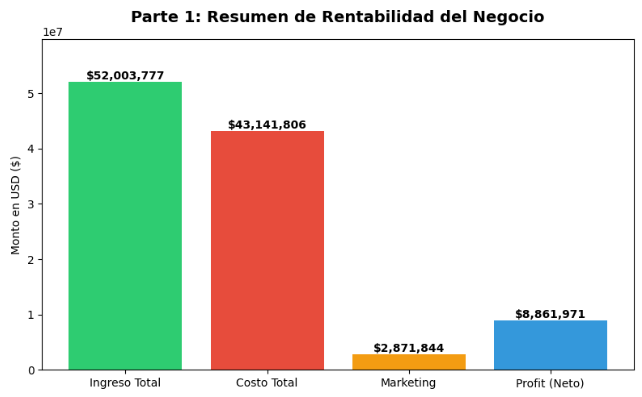
- El negocio obtiene valores positivos de beneficios de 8,861,971 millones.
- Inversión controlada en marketing: El gasto en marketing asciende a 2,871,844 millones, lo que representa un porcentaje moderado en relación con los ingresos totales (aproximadamente el 5.5%).

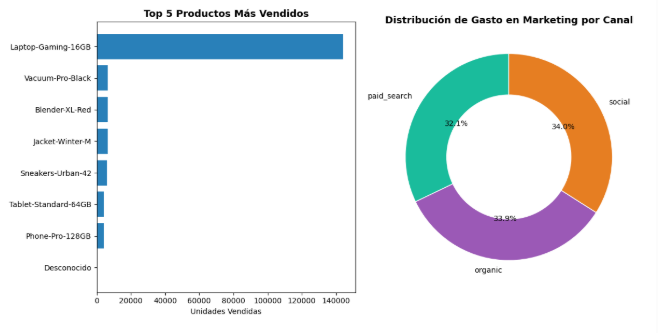
- Alta concentración en un "Producto Estrella": La Laptop-Gaming-16GB domina de forma absoluta y abrumadora las ventas con más de 140,000 unidades, el resto de productos tienen ventas muy marginales.
- Distribución equitativa de marketing: El presupuesto de adquisición se encuentra perfectamente repartido entre los canales de social (34.0%), organic (33.9%) y paid_search (32.1%), mostrando una estrategia equilibrada por canal.

## Funnel y Conversión

- Los usuarios no siguen un camino lineal, si no que aterrizan en la página de productos desde motores de busqueda, campañas o enlaces externos.
- El punto de mayor fricción para el usuario es cuando debe dar sus datos para poder realizar el pago.
- Si el usuario supera el punto de fricción mencionado este tiende a tener habitos de consumo bastante estables y estandarizados.

## Pruebas de hipotesis

- No se hayo una diferencia significativa entre la variante de control y de tratamiento respecto al tiempo de seción y la tasa conversión del usuario.
- No hay una relación significativa entre la región y la conversión del usuario.
- Se encontro una relación significativa entre el tipo de dispositivo y la conversión del usuario.

## Recomendaciones

- Mitigar la dependencia de producto: Dado que las ventas dependen abrumadoramente de la Laptop-Gaming-16GB, existe un riesgo operativo y financiero si este artículo pierde tendencia. Se recomienda impulsar estrategias de venta cruzada (cross-selling) o bundling para arrastrar el volumen de los demás productos del catálogo.
- Optimización del Retorno de Inversión (ROI) por canal: Aunque el gasto en marketing está muy equilibrado en tres tercios, es fundamental cruzar estos datos con la conversión real de cada canal.
- Se debe simplificar el método de pago para obtener mayor conversión de usuarios, como pasarelas de pago con un solo clic, reducir la cantidad de campos obligatorios para pagar.
- asegurar que el evento select_item se esté disparando correctamente y no existan vacíos en la captura de datos del catálogo.
- Descartar el cambio actual: Dado que la variante de tratamiento no mostró mejoras significativas frente al control en las métricas principales (conversión y tiempo de sesión), no se recomienda implementar este cambio en producción tal como está diseñado.
- Evaluar el comportamiento y la fricción que experimenta el usuario en los dispositivos moviles ya que estos tienen un número menor de usuarios que superan el funnel respecto a los usuarios que utilizan desktop.
 

---

## 🚀 Enlace a dashboard Power BI


In [67]:
https://drive.google.com/file/d/1rXl0XhmPS6EHixyVmhqYwgnMUDe4aVsF/view?usp=sharing
https://drive.google.com/drive/folders/1VJTLx-huAdIJuE2dkzGqfEkNWyeddbX_?usp=drive_link

SyntaxError: invalid syntax (544294116.py, line 1)